# Activité pratique n°2 — Modèles génératifs

**Nom :** Mohamed Ouallal  
**Classe :** IADATA — Groupe 4  
**Enseignant :** Mohamed YOUSSFI

## 0. Configuration de l’environnement


In [1]:
import sys
import torch
import torchvision
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torcheval
from torcheval.metrics import MulticlassAccuracy

assert sys.version_info[:2] == (3, 11), "Sélectionner l’environnement Python 3.11 du projet."
assert sys.prefix != sys.base_prefix, "Sélectionner l’environnement virtuel du projet."

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python :", sys.version.split()[0])
print("Environnement virtuel :", sys.prefix)
print("PyTorch :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Matplotlib :", matplotlib.__version__)
print("NumPy :", np.__version__)
print("Torcheval :", torcheval.__version__)
print("Appareil :", device)


Matplotlib is building the font cache; this may take a moment.


Python : 3.11.18
Environnement virtuel : /Users/mohamedouallal/emsi/5IIR/IAGEN/partie2/.venv
PyTorch : 2.15.0
Torchvision : 0.29.2
Matplotlib : 3.11.2
NumPy : 2.4.6
Torcheval : 0.0.7
Appareil : cpu


/Users/mohamedouallal/emsi/5IIR/IAGEN/partie2/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Chargement du dataset MNIST



In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Images d'entraînement :", len(train_dataset))
print("Images de test :", len(test_dataset))
print("Classes :", train_dataset.classes)


Images d’entraînement : 60000
Images de test : 10000
Classes : ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


Dimensions des images : torch.Size([128, 1, 28, 28])
Dimensions des étiquettes : torch.Size([128])
Type des images : torch.float32
Type des étiquettes : torch.int64
Valeurs des pixels : [0.0, 1.0]


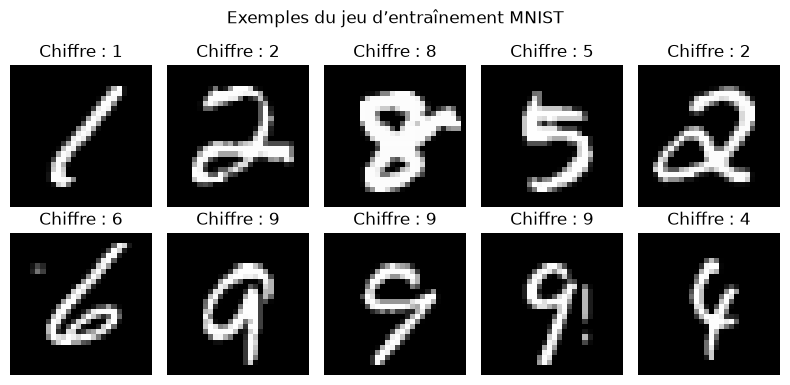

In [3]:
images, labels = next(iter(train_loader))

print("Dimensions des images :", images.shape)
print("Dimensions des étiquettes :", labels.shape)
print("Type des images :", images.dtype)
print("Type des étiquettes :", labels.dtype)
print(f"Valeurs des pixels : [{images.min().item():.1f}, {images.max().item():.1f}]")

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Chiffre : {labels[i].item()}")
    ax.axis("off")
plt.suptitle("Exemples du jeu d’entraînement MNIST")
plt.tight_layout()
plt.show()
